# Final catalog plots

## Imports and constants

In [255]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
from scipy import stats
import astropy


In [256]:
# Solar reference constants
LOGG_SUN = 4.438 
NUMAX_SUN = 3090.0
TEFF_SUN = 5777.0

## Load the catalog

In [257]:
# ==============================================================================
# 1. Load the Master Catalog
# ==============================================================================
data_path = '../data/extra_catalogs/'
df_master = pd.read_csv(data_path + 'K2_Kepler_TESS_x_GALAH_LAMOST.csv')

df_master


/tmp/ipykernel_16000/1534240344.py:5: DtypeWarning: Columns (2,3,65,68,70,79,81,83,97,98,100) have mixed types. Specify dtype option on import or set low_memory=False.
  df_master = pd.read_csv(data_path + 'K2_Kepler_TESS_x_GALAH_LAMOST.csv')


,K2_ID,K2_campaign,APOGEE_ID,ASPCAP_ID,GAIADR3_ID,numax,numax_err,Dnu,Dnu_err,L,...,__Fe_H_,A_Li_,DelA_Li_,e_DelA_Li_,Flag_lamost,Lim,DR7,Simbad,GALAH_ID,survey_match
0,210963423.0,4.0,2M03580051+2223476,apogee.apo25m.synspec_fix.169-24_btx.2M0358005...,1.636148e+18,41.2700,0.970000,4.42400,0.089000,53.742929,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,galah
1,206237975.0,3.0,2M22495022-0910174,apogee.apo25m.synspec_fix.K2_C3_059-57.2M22495...,1.636148e+18,36.5400,0.910000,4.28300,0.076000,29.428567,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,galah
2,213859399.0,7.0,2M19215425-2803444,apogee.apo25m.synspec_fix.K2_C7_009-18.2M19215...,1.636148e+18,185.0300,2.560000,12.12900,0.149000,13.221437,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,galah
3,220281055.0,8.0,2M00473607+0213443,apogee.apo25m.synspec_fix.120-60.2M00473607+02...,1.636148e+18,43.6600,1.100000,5.16400,0.088000,39.971368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,galah
4,211563796.0,5.0,2M08385616+1402110,apogee.apo25m.synspec_fix.K2_C5_212+30_btx.2M0...,1.636148e+18,28.3200,0.740000,3.43100,0.076000,80.258334,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,galah
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15079,201709364.0,1.0,NaN,NaN,NaN,140.1460,1.238260,11.94170,0.185113,11.752686,...,-0.25,1.2,0.1,0.1,1.0,0.0,30.0,Simbad,637603161.0,lamost
15080,220314877.0,8.0,NaN,NaN,NaN,172.1400,1.399170,13.90860,0.071162,9.627395,...,-0.24,1.2,0.0,0.0,0.0,1.0,106.0,Simbad,682208235.0,lamost
15081,210805381.0,4.0,NaN,NaN,NaN,37.1648,0.572836,4.16556,0.126208,54.506478,...,-0.11,1.0,0.1,0.0,1.0,0.0,10.0,Simbad,612215140.0,lamost
15082,211416360.0,16.0,NaN,NaN,NaN,158.5510,1.263040,13.14910,0.121042,10.277761,...,-0.20,1.0,0.0,0.0,1.0,0.0,108.0,Simbad,607104061.0,lamost


## Analyzing the Catalog Dataframe

In [258]:
df_master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15084 entries, 0 to 15083
Columns: 283 entries, K2_ID to survey_match
dtypes: bool(9), float64(256), int64(1), object(17)
memory usage: 31.7+ MB


In [259]:
#Primer objeto 
df_master.iloc[0] 
# this returns a pandas Series object, which is a one-dimensional array-like object 
# that can hold any data type. It has an index and a name, and it can be thought of as a single column 
# of a DataFrame. In this case, it returns the first row of the DataFrame df_master, with the index being
# the column names and the values being the corresponding values for that row.

K2_ID                                                 210963423.0
K2_campaign                                                   4.0
APOGEE_ID                                      2M03580051+2223476
ASPCAP_ID       apogee.apo25m.synspec_fix.169-24_btx.2M0358005...
GAIADR3_ID                                  1636148068921376768.0
                                      ...                        
Lim                                                           NaN
DR7                                                           NaN
Simbad                                                        NaN
GALAH_ID                                                      NaN
survey_match                                                galah
Name: 0, Length: 283, dtype: object

In [260]:
print(f"Value at [0, 0]: {df_master.iloc[0, 0]}") # returns just the value 

print(f"Value at [0, 'K2_campaign']: {df_master.loc[0, 'K2_campaign']}")  # This will return the value in the 'K2_ID' column for the first row 

Value at [0, 0]: 210963423.0
Value at [0, 'K2_campaign']: 4.0


In [261]:
df_master.iloc[[0],[0]] #this returns a DataFrame with a single value, rather than a Series. The double brackets indicate that we want to select a subset of the DataFrame, rather than a single row or column.


,K2_ID
0,210963423.0


In [262]:
df_master.loc[0:10, ['Dnu']]

,Dnu
0,4.424
1,4.283
2,12.129
3,5.164
4,3.431
5,4.178
6,3.522
7,10.465
8,10.088
9,3.935


In [263]:
df_master.loc[[0,1,2],['Dnu']]

,Dnu
0,4.424
1,4.283
2,12.129


In [264]:
df_master.iloc[0:10,[7]]

,Dnu
0,4.424
1,4.283
2,12.129
3,5.164
4,3.431
5,4.178
6,3.522
7,10.465
8,10.088
9,3.935


## Prepare Catalog

In [265]:
# ==============================================================================
# 0. Filter data that definitely is wrong 
# ==============================================================================

# ==============================================================================
# 1. Create masks for Galah and LAMOST data
# ==============================================================================

# pandas series of boolean values, where True indicates that the row meets the criteria for being a valid GALAH star, and False indicates that it does not.
galah_mask = (
    df_master['survey_match'].isin(['galah', 'both']) # when star encountered in both surveys, we consider it as a GALAH star
)

# This is just a pandas series of boolean values, where True indicates that the row meets the criteria for being a valid LAMOST star, and False indicates that it does not.
lamost_mask = (
    (df_master['survey_match'] == 'lamost')
)

goodgalah_mask = (
    (df_master['flag_sp'] == 0)
    &(df_master['snr_px_ccd3'] > 30)
)

goodlamost_mask = (
    (df_master['S_N_lamost'] > 20) # Not sure about putting this here of with Li_good_lamost
)

goodgalah_galah_mask = (
    (galah_mask)
    & (goodgalah_mask)
)

goodlamost_lamost_mask = (
    (lamost_mask)
    & (goodlamost_mask)
)

good_spectroscopy = (
    (goodlamost_mask) | (goodgalah_mask)
)

# ==============================================================================
# 2. Create masks for Willet data
# ==============================================================================

# The definition of this mask is horrible. I will change it next time I have to cross match.

K2_mask = (
    (df_master['K2_campaign'] < 200)
    &(df_master['K2_campaign'] != 0)
)

Kepler_mask = (
    (df_master['K2_campaign'] == 0)
)

TESS_mask = (
    (df_master['K2_campaign'] > 200)
)

# Definition of what is good or bad taken from Willet et al 2024

goodK2_mask =(
    ()
)

goodKepler_mask = (
    ()
)

goodTESS_mask = (
    ()
)


In [266]:
# ==============================================================================
# 3. Create masks for specific cases
# ==============================================================================

#Mask for good temperature in the kiel diagram
t_good_galah_mask = (
    goodgalah_galah_mask
    & df_master['teff'].notna()
)

t_good_lamost_mask = (
    goodlamost_lamost_mask
    & df_master['Teff_lamost'].notna()
)


# ==============================================================================
# 4.0 Some trials to select fe to prepare Unified Metallicity (with no clean mask)
# ==============================================================================
"""
# First some trials
df_master['feh'] = np.nan
df_master.loc[galah_mask, 'feh'] = pd.to_numeric(df_master.loc[galah_mask, 'fe_h_2'], errors='coerce')
df_master.loc[lamost_mask, 'feh'] = pd.to_numeric(df_master.loc[lamost_mask, '__Fe_H_'], errors='coerce')
df_master['feh'] = df_master['feh'].fillna(pd.to_numeric(df_master['Fe_H_1'], errors='coerce')) #If I want to use the Fe_H_1 (from APOGGE and GALAH) column as a backup for missing values, I can uncomment this line. It will fill in any NaN values in the 'feh' column with the corresponding values from the 'Fe_H_1' column, if they exist. 


df_master['feh2'] = np.nan
df_master.loc[galah_mask, 'feh2'] = pd.to_numeric(df_master.loc[galah_mask, 'fe_h_2'], errors='coerce')
df_master.loc[lamost_mask, 'feh2'] = pd.to_numeric(df_master.loc[lamost_mask, '__Fe_H_'], errors='coerce')

df_master['feh3'] = np.nan
df_master.loc[galah_mask, 'feh3'] = df_master.loc[galah_mask, 'fe_h_2']
df_master.loc[lamost_mask, 'feh3'] = df_master.loc[lamost_mask, '__Fe_H_']

# Check if feh and feh2 are identical (same values and same NaN/blank positions)

fe_p = 'feh'
fe_s = 'feh3'
same_feh = df_master[fe_p].equals(df_master[fe_s])
print(f"feh and feh2 are identical: {same_feh}")

if not same_feh:
    mask_diff = (
        (df_master[fe_p].isna() != df_master[fe_s].isna())
        | (
            df_master[fe_p].notna()
            & df_master[fe_s].notna()
            & (df_master[fe_p] != df_master[fe_s])
        )
    )
    print(df_master.loc[mask_diff, [fe_p, fe_s]].head())
    print(f"Number of rows with different values in 'feh' and 'feh2': {mask_diff.sum()} / {len(df_master)}")
"""




'\n# First some trials\ndf_master[\'feh\'] = np.nan\ndf_master.loc[galah_mask, \'feh\'] = pd.to_numeric(df_master.loc[galah_mask, \'fe_h_2\'], errors=\'coerce\')\ndf_master.loc[lamost_mask, \'feh\'] = pd.to_numeric(df_master.loc[lamost_mask, \'__Fe_H_\'], errors=\'coerce\')\ndf_master[\'feh\'] = df_master[\'feh\'].fillna(pd.to_numeric(df_master[\'Fe_H_1\'], errors=\'coerce\')) #If I want to use the Fe_H_1 (from APOGGE and GALAH) column as a backup for missing values, I can uncomment this line. It will fill in any NaN values in the \'feh\' column with the corresponding values from the \'Fe_H_1\' column, if they exist. \n\n\ndf_master[\'feh2\'] = np.nan\ndf_master.loc[galah_mask, \'feh2\'] = pd.to_numeric(df_master.loc[galah_mask, \'fe_h_2\'], errors=\'coerce\')\ndf_master.loc[lamost_mask, \'feh2\'] = pd.to_numeric(df_master.loc[lamost_mask, \'__Fe_H_\'], errors=\'coerce\')\n\ndf_master[\'feh3\'] = np.nan\ndf_master.loc[galah_mask, \'feh3\'] = df_master.loc[galah_mask, \'fe_h_2\']\ndf_ma

In [267]:
# ==============================================================================
# 4.1 Prepare Unified quantities (with no clean mask just everything)
# ==============================================================================

# Unified metallicity
   
df_master['feh'] = np.nan
df_master.loc[galah_mask, 'feh'] = pd.to_numeric(df_master.loc[galah_mask, 'fe_h_2'], errors='coerce')
df_master.loc[lamost_mask, 'feh'] = pd.to_numeric(df_master.loc[lamost_mask, '__Fe_H_'], errors='coerce')

# Unified temperature

df_master['Teff_kiel'] = np.nan
df_master['Teff_source'] = np.nan

df_master.loc[galah_mask, 'Teff_kiel'] = pd.to_numeric(df_master.loc[galah_mask, 'teff'], errors='coerce')
df_master.loc[galah_mask, 'Teff_source'] = 'GALAH'

df_master.loc[lamost_mask, 'Teff_kiel'] = pd.to_numeric(df_master.loc[lamost_mask, 'Teff_lamost'], errors='coerce')
df_master.loc[lamost_mask, 'Teff_source'] = 'LAMOST'



/tmp/ipykernel_16000/1153574354.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'GALAH' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_master.loc[galah_mask, 'Teff_source'] = 'GALAH'


## Studying the population in the Catalog

### Kiel Diagram

In this section we construct a **Kiel Diagram** ($\log g$ vs. $T_{\mathrm{eff}}$) using the master catalog `K2_Kepler_TESS_x_GALAH_LAMOST.csv`.

#### 1. Effective Temperature ($T_{\mathrm{eff}}$) & Survey Flags
* **GALAH** (`survey_match` in `['galah', 'both']`):
  * $T_{\mathrm{eff}}$ taken from `teff`.
  * Quality filter: `flag_sp == 0` (reliable spectroscopic analysis).
* **LAMOST** (`survey_match == 'lamost'`):
  * $T_{\mathrm{eff}}$ taken from `Teff_lamost`.
  * Quality filter: `S_N_lamost > 20` (recommended by Ding et al. 2024).

#### 2. Surface Gravity ($\log g$) from Asteroseismic Scaling Relations
Surface gravity is related to mass and radius by:
$$g = \frac{G M}{R^2} \implies \frac{g}{g_\odot} = \frac{M/M_\odot}{(R/R_\odot)^2}$$
$$\log g = \log g_\odot + \log_{10}\left(\frac{M}{M_\odot}\right) - 2\log_{10}\left(\frac{R}{R_\odot}\right)$$
with $\log g_\odot = 4.438\text{ dex}$.

This is directly consistent with the $\nu_{\max}$ scaling relation:
$$\frac{\nu_{\max}}{\nu_{\max,\odot}} \approx \left(\frac{g}{g_\odot}\right)\left(\frac{T_{\mathrm{eff}}}{T_{\mathrm{eff},\odot}}\right)^{-1/2} \implies \log g = \log g_\odot + \log_{10}\left(\frac{\nu_{\max}}{\nu_{\max,\odot}}\right) + \frac{1}{2}\log_{10}\left(\frac{T_{\mathrm{eff}}}{T_{\mathrm{eff},\odot}}\right)$$

Except that the Teff must be obtained in another way (spectroscopy or photometry). In our case, because we are trying to construct a Kiel diagram a possible problem in teff would introduce a degeneracy in the plot.

In Willet et al., $M$ and $R$ were derived using asteroseismic scaling relations and grid modeling:
* **$\Delta\nu$-constrained**: `mass_Dnu` and `rad_Dnu`, filtered by `RelAge_Dnu == True`.
* **$L$-constrained**: `mass_L` and `rad_L`, filtered by `RelAge_L == True`.

In [268]:
# Assign some columns to variables for simpler use

mass_dnu = pd.to_numeric(df_master['mass_Dnu'], errors='coerce')
rad_dnu = pd.to_numeric(df_master['rad_Dnu'], errors='coerce')
numax = pd.to_numeric(df_master['numax'], errors='coerce')


# Compute using MASS and Radius delta nu constrained 
rel_age_dnu = df_master['RelAge_Dnu'].astype(str).str.lower() == 'true' # when using mass and radius this is  required
valid_dnu = rel_age_dnu

#Compute logg using the Willet mass and radius scaling relation:
df_master['logg_willet_dnu'] = np.nan
df_master.loc[valid_dnu, 'logg_willet_dnu'] = (
    LOGG_SUN + np.log10(mass_dnu[valid_dnu]) - 2.0 * np.log10(rad_dnu[valid_dnu])
    #logg = logg_sun + log10(M/Msun) - 2*log10(R/Rsun)
)

# Compute using direct numax scaling adn T_eff relation for comparison:

valid_vmax = pd.Series(True, index=valid_dnu.index) # 
 #valid_dnu & df_master['Teff_kiel'].notna() #because here it is valid_dnu, it is rel_age_dnu which is not necessary here, try removing it


df_master['logg_teff_scaling'] = np.nan
df_master.loc[valid_vmax, 'logg_teff_scaling'] = (
    LOGG_SUN + np.log10(numax[valid_vmax] / NUMAX_SUN) + 0.5 * np.log10(df_master.loc[valid_vmax, 'Teff_kiel'] / TEFF_SUN)
)

"""
# --- Branch B: L-constrained sample (RelAge_L == True) --- for comparison again. Not used
rel_age_l = df_master['RelAge_L'].astype(str).str.lower() == 'true'
mass_l = pd.to_numeric(df_master['mass_L'], errors='coerce')
rad_l = pd.to_numeric(df_master['rad_L'], errors='coerce')
valid_l = rel_age_l & (mass_l > 0) & (rad_l > 0)

df_master['logg_willet_l'] = np.nan
df_master.loc[valid_l, 'logg_willet_l'] = (
    LOGG_SUN + np.log10(mass_l[valid_l]) - 2.0 * np.log10(rad_l[valid_l])
)
"""

kiel_sample_M_R = df_master.dropna(subset=['Teff_kiel', 'logg_willet_dnu', 'feh']).copy()
kiel_sample_teff = df_master.dropna(subset=['Teff_kiel', 'logg_teff_scaling', 'feh']).copy()


print(f"Total stars in master catalog: {len(df_master)}")
print(f"Clean stars for Kiel Diagram (Dnu constraint): {len(kiel_sample_M_R)}")
print(f"Breakdown by survey: {kiel_sample_M_R['Teff_source'].value_counts().to_dict()}")
print(f"Teff range: {kiel_sample_M_R['Teff_kiel'].min():.0f} K - {kiel_sample_M_R['Teff_kiel'].max():.0f} K")
print(f"logg range: {kiel_sample_M_R['logg_willet_dnu'].min():.2f} - {kiel_sample_M_R['logg_willet_dnu'].max():.2f} dex")


Total stars in master catalog: 15084
Clean stars for Kiel Diagram (Dnu constraint): 6208
Breakdown by survey: {'GALAH': 3912, 'LAMOST': 2296}
Teff range: 3701 K - 6159 K
logg range: 2.10 - 3.36 dex


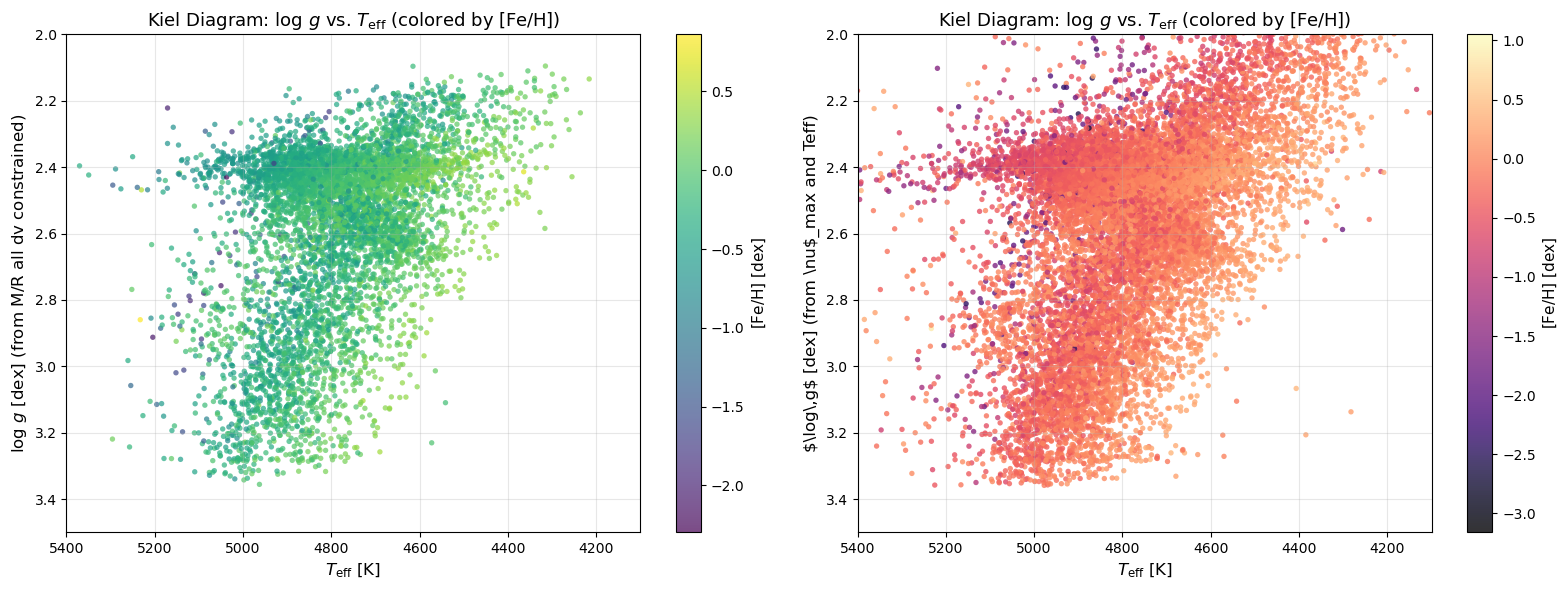

In [269]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel 1: Kiel Diagram Colored by Metallicity [Fe/H] ---
ax1 = axes[0]
sc1 = ax1.scatter(
    kiel_sample_M_R['Teff_kiel'],
    kiel_sample_M_R['logg_willet_dnu'],
    c=kiel_sample_M_R['feh'],
    cmap='viridis',
    s=15,
    alpha=0.7,
    edgecolors='none'
)

ax1.set_xlim(5400, 4100)  # Inverted Teff (hot on left, cool on right)
ax1.set_ylim(3.5, 2.0)    # Inverted logg (high logg at bottom, low at top)
ax1.set_xlabel(r'$T_{\mathrm{eff}}$ [K]', fontsize=12)
ax1.set_ylabel(r'$\log\,g$ [dex] (from M/R all dv constrained)', fontsize=12)
ax1.set_title(r'Kiel Diagram: $\log\,g$ vs. $T_{\mathrm{eff}}$ (colored by [Fe/H])', fontsize=13)
ax1.grid(True, alpha=0.3)
cb1 = plt.colorbar(sc1, ax=ax1)
cb1.set_label(r'$[\mathrm{Fe/H}]$ [dex]', fontsize=11)

# --- Panel 2: Kiel Diagram Colored by Density (Gaussian KDE) ---
ax2 = axes[1]
sc2 = ax2.scatter(
    kiel_sample_teff['Teff_kiel'], 
    kiel_sample_teff['logg_teff_scaling'],
    c=kiel_sample_teff['feh'],
    cmap='magma',
    s=15,
    alpha=0.8,
    edgecolors='none'
)

ax2.set_xlim(5400, 4100)  # Inverted Teff
ax2.set_ylim(3.5, 2.0)    # Inverted logg
ax2.set_xlabel(r'$T_{\mathrm{eff}}$ [K]', fontsize=12)
ax2.set_ylabel(r'$\log\,g$ [dex] (from \nu$_max and Teff)', fontsize=12)
ax2.set_title(r'Kiel Diagram: $\log\,g$ vs. $T_{\mathrm{eff}}$ (colored by [Fe/H])', fontsize=13)
ax2.grid(True, alpha=0.3)
cb2 = plt.colorbar(sc2, ax=ax2)
cb2.set_label(r'$[\mathrm{Fe/H}]$ [dex]', fontsize=11)

plt.tight_layout()
plt.show()


In [270]:
valid = kiel_sample_M_R[['logg_teff_scaling', 'logg_willet_dnu']].dropna()

# strict comparison
n_diff = (valid['logg_teff_scaling'] != valid['logg_willet_dnu']).sum()

# if you want to allow tiny floating-point noise instead, use:
n_diff = (~np.isclose(valid['logg_teff_scaling'].to_numpy(),
                      valid['logg_willet_dnu'].to_numpy(),
                      rtol=1e-2, atol=1e-2)).sum()

print(f"Number of stars with different logg values: {n_diff} / {len(valid)} for a tolerance of 0.01 dex")

Number of stars with different logg values: 56 / 6208 for a tolerance of 0.01 dex


#### NO filter Kiel diagram

In [271]:
# Compute logg using the Willet mass and radius scaling relation:
# logg = logg_sun + log10(M/Msun) - 2*log10(R/Rsun)
df_master['logg_willet_dnu'] = LOGG_SUN + np.log10(mass_dnu) - 2.0 * np.log10(rad_dnu)
kiel_sample_M_R = df_master.dropna(subset=['Teff_kiel', 'logg_willet_dnu', 'feh']).copy()

print(f"Total stars in master catalog: {len(df_master)}")
print(f"Clean stars for Kiel Diagram (Dnu constraint): {len(kiel_sample_M_R)}")
print(f"Breakdown by survey: {kiel_sample_M_R['Teff_source'].value_counts().to_dict()}")
print(f"Teff range: {kiel_sample_M_R['Teff_kiel'].min():.0f} K - {kiel_sample_M_R['Teff_kiel'].max():.0f} K")
print(f"logg range: {kiel_sample_M_R['logg_willet_dnu'].min():.2f} - {kiel_sample_M_R['logg_willet_dnu'].max():.2f} dex")

Total stars in master catalog: 15084
Clean stars for Kiel Diagram (Dnu constraint): 9637
Breakdown by survey: {'GALAH': 6403, 'LAMOST': 3234}
Teff range: 3395 K - 7536 K
logg range: 1.17 - 3.38 dex


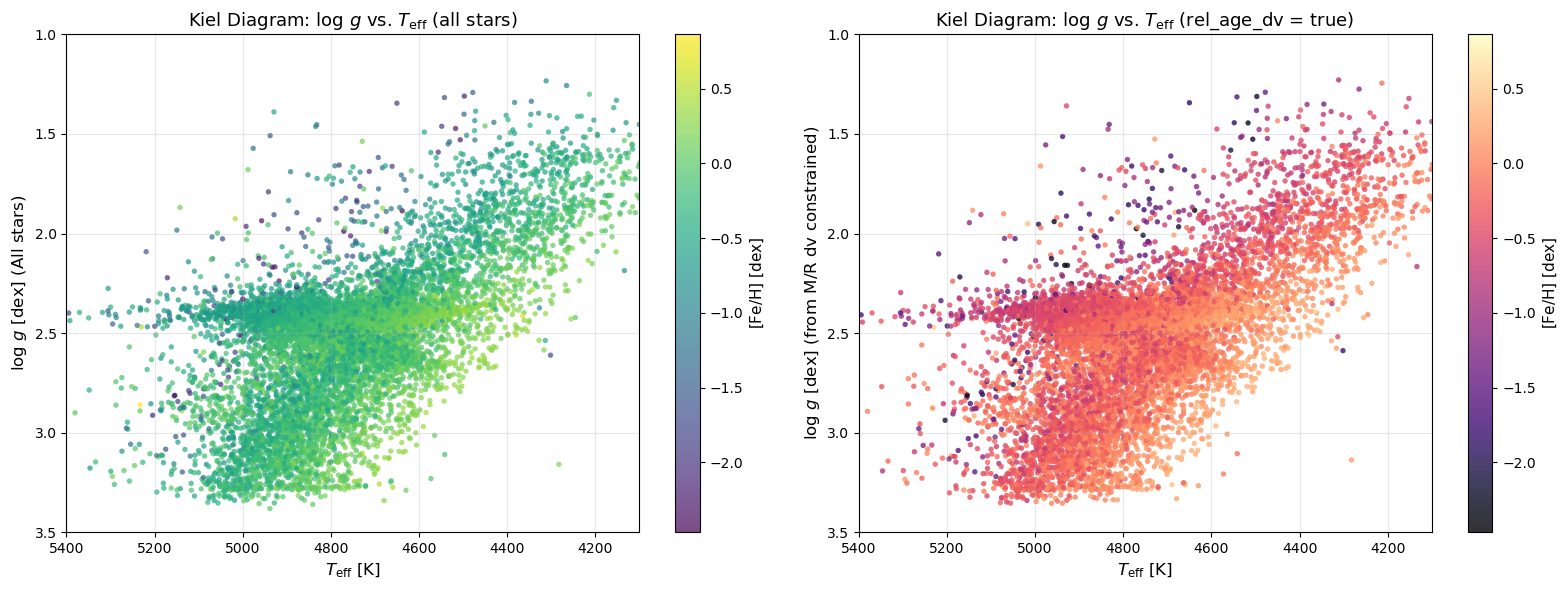

In [272]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel 1: Kiel Diagram Colored by Metallicity [Fe/H] ---
ax1 = axes[0]
sc1 = ax1.scatter(
    kiel_sample_M_R['Teff_kiel'],
    kiel_sample_M_R['logg_willet_dnu'],
    c=kiel_sample_M_R['feh'],
    cmap='viridis',
    s=15,
    alpha=0.7,
    edgecolors='none'
)

ax1.set_xlim(5400, 4100)  # Inverted Teff (hot on left, cool on right)
ax1.set_ylim(3.5, 1.0)    # Inverted logg (high logg at bottom, low at top)
ax1.set_xlabel(r'$T_{\mathrm{eff}}$ [K]', fontsize=12)
ax1.set_ylabel(r'$\log\,g$ [dex] (All stars)', fontsize=12)
ax1.set_title(r'Kiel Diagram: $\log\,g$ vs. $T_{\mathrm{eff}}$ (all stars)', fontsize=13)
ax1.grid(True, alpha=0.3)
cb1 = plt.colorbar(sc1, ax=ax1)
cb1.set_label(r'$[\mathrm{Fe/H}]$ [dex]', fontsize=11)

# --- Panel 2: Kiel Diagram Colored by Density (Gaussian KDE) ---
ax2 = axes[1]
sc2 = ax2.scatter(
    kiel_sample_M_R['Teff_kiel'], 
    kiel_sample_M_R['logg_teff_scaling'],
    c=kiel_sample_M_R['feh'],
    cmap='magma',
    s=15,
    alpha=0.8,
    edgecolors='none'
)

ax2.set_xlim(5400, 4100)  # Inverted Teff
ax2.set_ylim(3.5, 1.0)    # Inverted logg
ax2.set_xlabel(r'$T_{\mathrm{eff}}$ [K]', fontsize=12)
ax2.set_ylabel(r'$\log\,g$ [dex] (from M/R dv constrained)', fontsize=12)
ax2.set_title(r'Kiel Diagram: $\log\,g$ vs. $T_{\mathrm{eff}}$ (rel_age_dv = true) ', fontsize=13)
ax2.grid(True, alpha=0.3)
cb2 = plt.colorbar(sc2, ax=ax2)
cb2.set_label(r'$[\mathrm{Fe/H}]$ [dex]', fontsize=11)

plt.tight_layout()
plt.show()


#### Kiel diagram of RGB and RC separate

In [273]:
### More masksss. This time to differentciate evolutionay states. We use Willet et al 2024 as reference

RGB_mask = (
    (df_master['L'] < 35)
    &(df_master['logg_willet_dnu'] > 2.6)
)

CHeB_mask = (
    (df_master['L'] >= 35)
    &(df_master['logg_willet_dnu'] < 2.5)
)



# Initialize Kiel diagram columns
df_master['Teff_kiel'] = np.nan
df_master['Teff_source'] = np.nan

df_master.loc[t_good_galah_mask, 'Teff_kiel'] = pd.to_numeric(df_master.loc[t_good_galah_mask, 'teff'], errors='coerce')
df_master.loc[t_good_galah_mask, 'Teff_source'] = 'GALAH'


df_master.loc[t_good_lamost_mask, 'Teff_kiel'] = pd.to_numeric(df_master.loc[t_good_lamost_mask, 'Teff_lamost'], errors='coerce')
df_master.loc[t_good_lamost_mask, 'Teff_source'] = 'LAMOST'

kiel_sample_M_R = df_master.dropna(subset=['Teff_kiel', 'logg_willet_dnu', 'feh']).copy()



/tmp/ipykernel_16000/1824186565.py:20: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'GALAH' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_master.loc[t_good_galah_mask, 'Teff_source'] = 'GALAH'


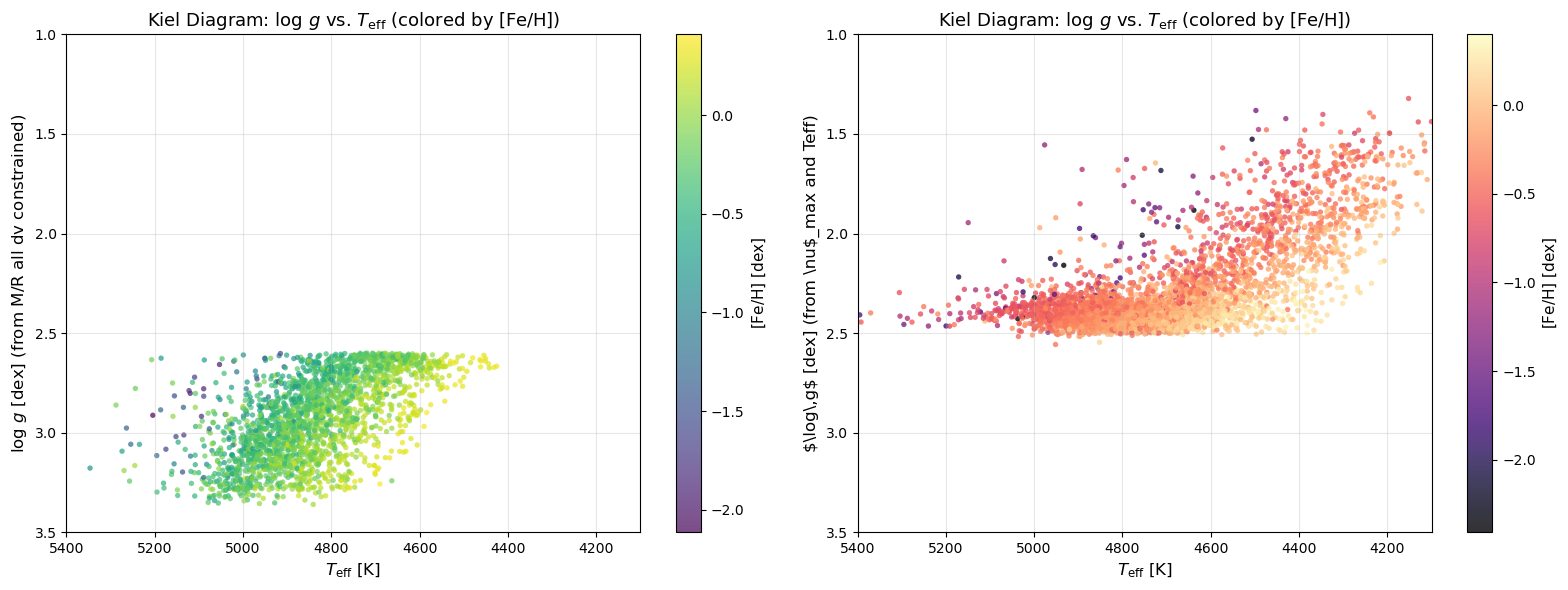

In [274]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel 1: Kiel Diagram Colored by Metallicity [Fe/H] ---
ax1 = axes[0]
sc1 = ax1.scatter(
    kiel_sample_M_R.loc[RGB_mask ,'Teff_kiel'],
    kiel_sample_M_R.loc[RGB_mask, 'logg_willet_dnu'],
    c=kiel_sample_M_R.loc[RGB_mask,'feh'],
    cmap='viridis',
    s=15,
    alpha=0.7,
    edgecolors='none'
)

ax1.set_xlim(5400, 4100)  # Inverted Teff (hot on left, cool on right)
ax1.set_ylim(3.5, 1.0)    # Inverted logg (high logg at bottom, low at top)
ax1.set_xlabel(r'$T_{\mathrm{eff}}$ [K]', fontsize=12)
ax1.set_ylabel(r'$\log\,g$ [dex] (from M/R all dv constrained)', fontsize=12)
ax1.set_title(r'Kiel Diagram: $\log\,g$ vs. $T_{\mathrm{eff}}$ (colored by [Fe/H])', fontsize=13)
ax1.grid(True, alpha=0.3)
cb1 = plt.colorbar(sc1, ax=ax1)
cb1.set_label(r'$[\mathrm{Fe/H}]$ [dex]', fontsize=11)

# --- Panel 2: Kiel Diagram Colored by Density (Gaussian KDE) ---
ax2 = axes[1]
sc2 = ax2.scatter(
    kiel_sample_M_R.loc[CHeB_mask,'Teff_kiel'], 
    kiel_sample_M_R.loc[CHeB_mask,'logg_teff_scaling'],
    c=kiel_sample_M_R.loc[CHeB_mask,'feh'],
    cmap='magma',
    s=15,
    alpha=0.8,
    edgecolors='none'
)

ax2.set_xlim(5400, 4100)  # Inverted Teff
ax2.set_ylim(3.5, 1.0)    # Inverted logg
ax2.set_xlabel(r'$T_{\mathrm{eff}}$ [K]', fontsize=12)
ax2.set_ylabel(r'$\log\,g$ [dex] (from \nu$_max and Teff)', fontsize=12)
ax2.set_title(r'Kiel Diagram: $\log\,g$ vs. $T_{\mathrm{eff}}$ (colored by [Fe/H])', fontsize=13)
ax2.grid(True, alpha=0.3)
cb2 = plt.colorbar(sc2, ax=ax2)
cb2.set_label(r'$[\mathrm{Fe/H}]$ [dex]', fontsize=11)

plt.tight_layout()
plt.show()


### Li abundances vs Iron

In [275]:
li_good_galah_mask = (
    goodgalah_galah_mask
    &(df_master['flag_a_li'] == False)
)

li_good_lamost_mask = (
    goodlamost_lamost_mask
    &(df_master['Lim'] == 0) 
)


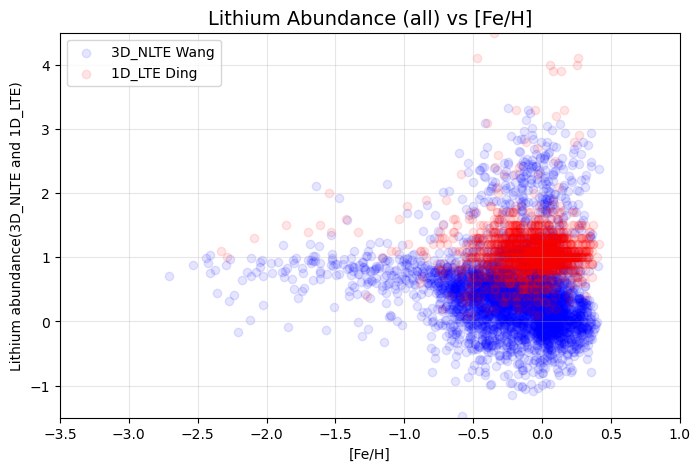

In [276]:
plt.figure(figsize=(8, 5))
plt.scatter(df_master[li_good_galah_mask]['fe_h_2'], df_master[li_good_galah_mask]['a_li'], alpha=0.1, c='blue', label='3D_NLTE Wang')
plt.scatter(df_master[li_good_lamost_mask]['__Fe_H_'], df_master[li_good_lamost_mask]['A_Li_'], alpha=0.1, c='red', label='1D_LTE Ding')
plt.grid(True, alpha=0.3)
plt.legend()

plt.xlim(-3.5, 1.0)
plt.ylim(-1.5, 4.5)

plt.title('Lithium Abundance (all) vs [Fe/H]', fontsize=14)
plt.xlabel('[Fe/H]')
plt.ylabel('Lithium abundance(3D_NLTE and 1D_LTE)')
plt.show()

### Kinematics

#### Toomre diagram

##### Toomre diagram Cartesian coord

A Toomre diagram is a scatter plot used to distinguish kinematically between the different conponents of the Milky Way. It plots the velocities of each individual star, with respect to a Local Standart of Reference (LSR). 

In [277]:
print([col for col in df_master.columns if "ra" in col])
print([col for col in df_master.columns if "dec" in col])
print([col for col in df_master.columns if col in ["vR", "vT", "vZ"]])
print([col for col in df_master.columns if col.startswith("warn_")])

['rad_Dnu', 'rad_16_Dnu', 'rad_84_Dnu', 'rad_L', 'rad_16_L', 'rad_84_L', 'ra', 'parallax', 'parallax_error']
['dec']
['vR', 'vT', 'vZ']
['warn_low_numax', 'warn_high_Dnu', 'warn_high_RUWE', 'warn_NSS', 'warn_APOGEE', 'warn_plax_err', 'warn_dustmaps', 'warn_nve_Av_Dnu', 'warn_nve_Av_L', 'warn_massdiff']


In [278]:
print(df_master['RelAge_Dnu'].value_counts(dropna=False))

RelAge_Dnu
True     8355
False    6729
Name: count, dtype: int64


In [279]:
print(df_master[['vR', 'vT', 'vZ']].describe())

                 vR            vT            vZ
count  14263.000000  14263.000000  14263.000000
mean       3.511825    183.568590     -4.206462
std       94.546458     93.562226     69.132871
min    -1719.470322  -4076.938010  -2664.774585
25%      -30.063586    171.225044    -17.930520
50%        1.522271    200.155142     -0.801560
75%       33.278147    221.077954     15.445872
max     4565.092566   1270.466100    870.203341


Text(0, 0.5, '$\\sqrt{v_X^2+v_Z^2}$ [km/s]')

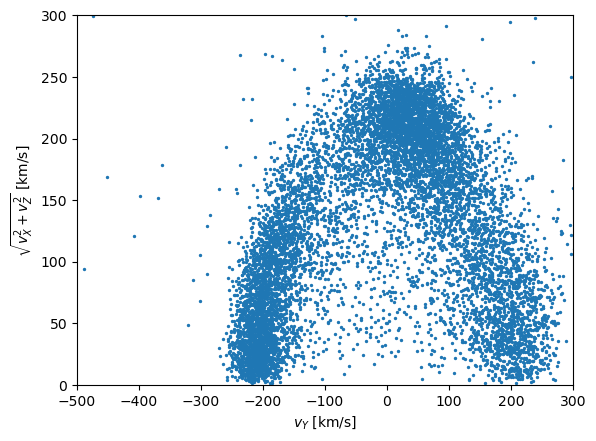

In [280]:

from astropy.coordinates import SkyCoord, Galactocentric
import astropy.units as u

# when cross matching sometimes I put in the same column two different things, maybe I will change this 
# in the future, so I only have to change the key and not everywhere in the code.

general_ra_key = 'ra' #Column originally from GALAH but also has LAMOST ra  
general_dec_key = 'dec' # same
general_telescope_ID = 'K2_ID'
general_2mass_ID_unformated = 'APOGEE_ID'
general_alpha_over_fe_or_metal = 'alpha_M'

cols_needed = [general_ra_key, general_dec_key, 'dist_Dnu', 'vR', 'vT', 'vZ']

# 1. Force everything in these columns to be numeric. Empty strings/text become NaN.
for col in cols_needed:
    df_master[col] = pd.to_numeric(df_master[col], errors='coerce')

# 2. Now the mask will successfully catch all the missing data
mask_kinematics = df_master[cols_needed].notna().all(axis=1)

mask_kinematics = mask_kinematics

# Pass the masked subset directly to your function/plot without saving a new variable
c = SkyCoord(
    ra=df_master.loc[mask_kinematics, general_ra_key].to_numpy() * u.deg, 
    dec=df_master.loc[mask_kinematics, general_dec_key].to_numpy() * u.deg, 
    distance=df_master.loc[mask_kinematics, 'dist_Dnu'].to_numpy() * u.kpc, 
    frame='icrs'
)


#We only have proper motion for GALAH, no LAMOST

gc = c.transform_to(Galactocentric())
phi = np.arctan2(gc.y.value, gc.x.value)


v_X = df_master.loc[mask_kinematics,'vR'].to_numpy()*np.cos(phi) - df_master.loc[mask_kinematics,'vT'].to_numpy()*np.sin(phi)
v_Y = df_master.loc[mask_kinematics,'vR'].to_numpy()*np.sin(phi) + df_master.loc[mask_kinematics,'vT'].to_numpy()*np.cos(phi)
v_Z = df_master.loc[mask_kinematics,'vZ'].to_numpy()

# Ploting

toomre_y = np.sqrt(v_X**2 + v_Z**2)
plt.ylim(0,300)
plt.xlim(-500,300)
plt.scatter(v_Y, toomre_y, s=2)
plt.xlabel(r'$v_Y$ [km/s]')
plt.ylabel(r'$\sqrt{v_X^2+v_Z^2}$ [km/s]')



VT, VZ and VR show the same pattern in the histogram, so they are clean from suspicious
Also RA and DEC of GALAH (GAIA) and LAMOST show the same pttern in the histogram, they are homogenious 

Text(0.5, 0, 'RA')

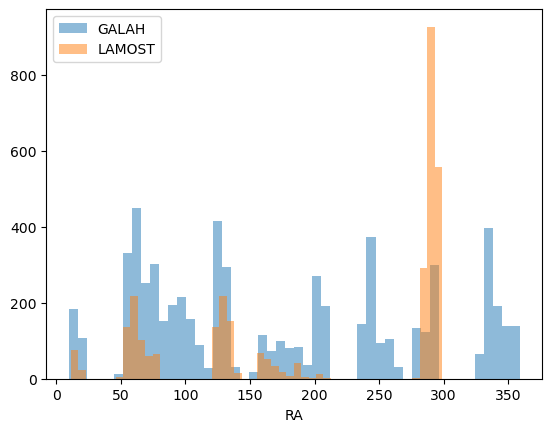

In [281]:
df_sub= df_master.loc[mask_kinematics].copy()
df_sub['phi'] = phi  # from your code above

# Do you have a column distinguishing GALAH vs LAMOST rows? Use it here.
# If not, infer it from which ID columns are non-null, e.g.:
#is_galah = df_sub['APOGEE_ID'].notna()  # or whatever flags GALAH rows



plt.hist(df_sub.loc[galah_mask, 'ra'], bins=50, alpha=0.5, label='GALAH')
plt.hist(df_sub.loc[lamost_mask, 'ra'], bins=50, alpha=0.5, label='LAMOST')
plt.legend(); plt.xlabel('RA')

Text(0.5, 0, 'DEC')

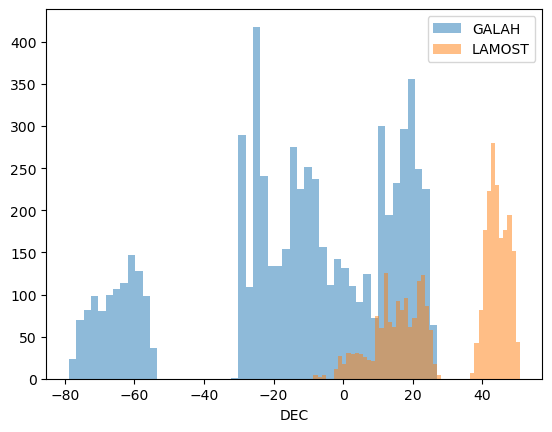

In [282]:
df_sub= df_master.loc[mask_kinematics].copy()
df_sub['phi'] = phi  # from your code above

# Do you have a column distinguishing GALAH vs LAMOST rows? Use it here.
# If not, infer it from which ID columns are non-null, e.g.:
#is_galah = df_sub['APOGEE_ID'].notna()  # or whatever flags GALAH rows



plt.hist(df_sub.loc[galah_mask, 'dec'], bins=50, alpha=0.5, label='GALAH')
plt.hist(df_sub.loc[lamost_mask, 'dec'], bins=50, alpha=0.5, label='LAMOST')
plt.legend(); plt.xlabel('DEC')

##### Toomre diagram in Cilindrical coord


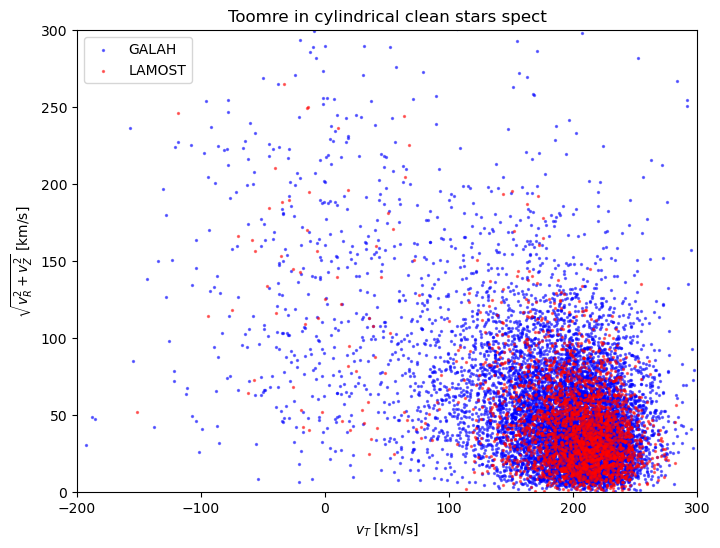

In [283]:

# Calculate Toomre y-axis values for both masks
toomre_y_galah = np.sqrt(df_master.loc[goodgalah_galah_mask, 'vR']**2 + df_master.loc[goodgalah_galah_mask, 'vZ']**2)
toomre_y_lamost = np.sqrt(df_master.loc[goodlamost_lamost_mask, 'vR']**2 + df_master.loc[goodlamost_lamost_mask, 'vZ']**2)

plt.figure(figsize=(8, 6))
plt.ylim(0, 300)
plt.xlim(-200, 300)

# Plot GALAH data (e.g., in blue)
plt.scatter(df_master.loc[goodgalah_galah_mask, 'vT'], toomre_y_galah, 
            s=2, c='blue', alpha=0.5, label='GALAH')

# Plot LAMOST data (e.g., in red)
plt.scatter(df_master.loc[goodlamost_lamost_mask, 'vT'], toomre_y_lamost, 
            s=2, c='red', alpha=0.5, label='LAMOST')

plt.xlabel(r'$v_T$ [km/s]')
plt.ylabel(r'$\sqrt{v_R^2+v_Z^2}$ [km/s]')
plt.title('Toomre in cylindrical clean stars spect')
plt.legend() # Adds the legend to differentiate the colors
plt.show()

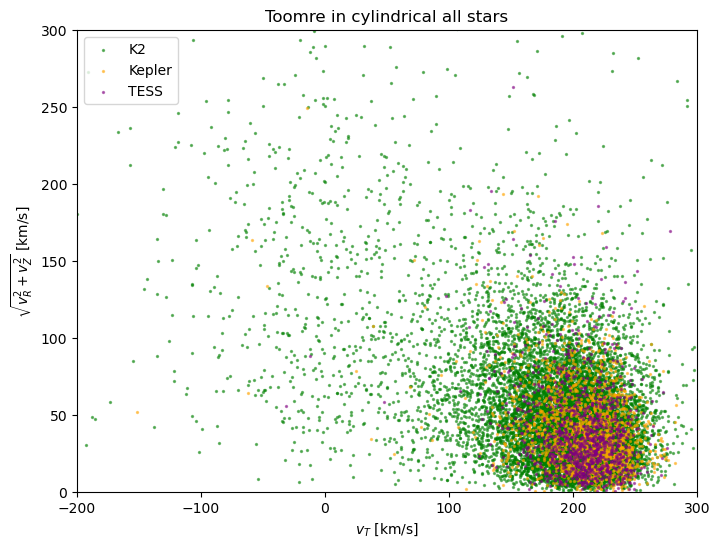

In [284]:


# Calculate Toomre y-axis values for each mask
toomre_y_k2 = np.sqrt(df_master.loc[K2_mask, 'vR']**2 + df_master.loc[K2_mask,'vZ']**2)
toomre_y_kepler = np.sqrt(df_master.loc[Kepler_mask, 'vR']**2 + df_master.loc[Kepler_mask, 'vZ']**2)
toomre_y_tess = np.sqrt(df_master.loc[TESS_mask, 'vR']**2 + df_master.loc[TESS_mask, 'vZ']**2)

plt.figure(figsize=(8, 6))
plt.ylim(0, 300)
plt.xlim(-200, 300)

# Plot K2 data
plt.scatter(df_master.loc[K2_mask, 'vT'], toomre_y_k2, 
            s=2, c='green', alpha=0.5, label='K2')

# Plot Kepler data
plt.scatter(df_master.loc[Kepler_mask, 'vT'], toomre_y_kepler, 
            s=2, c='orange', alpha=0.5, label='Kepler')

# Plot TESS data
plt.scatter(df_master.loc[TESS_mask, 'vT'], toomre_y_tess, 
            s=2, c='purple', alpha=0.5, label='TESS')

plt.xlabel(r'$v_T$ [km/s]')
plt.ylabel(r'$\sqrt{v_R^2+v_Z^2}$ [km/s]')
plt.title('Toomre in cylindrical all stars')
plt.legend()
plt.show()

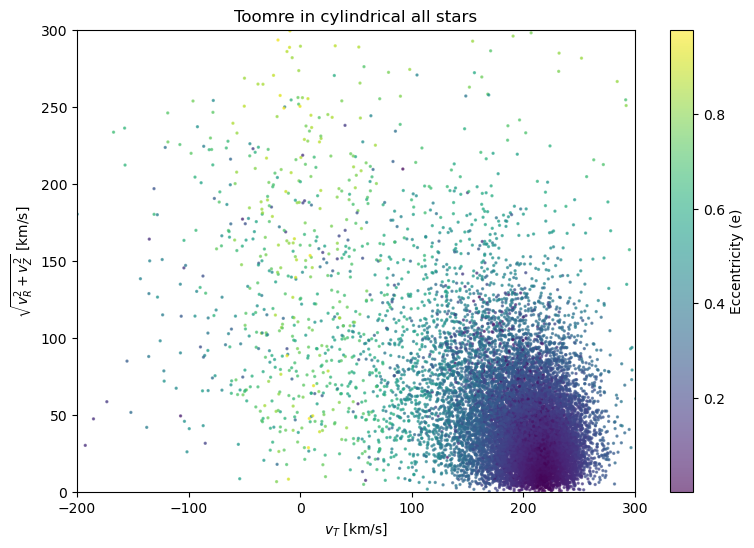

In [285]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate Toomre y-axis values for each mask
toomre_y_k2 = np.sqrt(df_master.loc[K2_mask, 'vR']**2 + df_master.loc[K2_mask, 'vZ']**2)
toomre_y_kepler = np.sqrt(df_master.loc[Kepler_mask, 'vR']**2 + df_master.loc[Kepler_mask, 'vZ']**2)
toomre_y_tess = np.sqrt(df_master.loc[TESS_mask, 'vR']**2 + df_master.loc[TESS_mask, 'vZ']**2)

# Get eccentricity values for each mask
e_k2 = df_master.loc[K2_mask, 'e']
e_kepler = df_master.loc[Kepler_mask, 'e']
e_tess = df_master.loc[TESS_mask, 'e']

# Calculate global min and max eccentricity to keep the color scale consistent
vmin = min(e_k2.min(), e_kepler.min(), e_tess.min())
vmax = max(e_k2.max(), e_kepler.max(), e_tess.max())

# Make the figure slightly wider to comfortably fit the colorbar
plt.figure(figsize=(9, 6))
plt.ylim(0, 300)
plt.xlim(-200, 300)

# Choose a colormap (e.g., 'viridis', 'plasma', 'cividis')
cmap = 'viridis'

# Plot K2 data
plt.scatter(df_master.loc[K2_mask, 'vT'], toomre_y_k2, 
            s=2, c=e_k2, cmap=cmap, vmin=vmin, vmax=vmax, alpha=0.6, label='K2')

# Plot Kepler data
plt.scatter(df_master.loc[Kepler_mask, 'vT'], toomre_y_kepler, 
            s=2, c=e_kepler, cmap=cmap, vmin=vmin, vmax=vmax, alpha=0.6, label='Kepler')

# Plot TESS data (saved as 'sc' so we can link the colorbar to it)
sc = plt.scatter(df_master.loc[TESS_mask, 'vT'], toomre_y_tess, 
                 s=2, c=e_tess, cmap=cmap, vmin=vmin, vmax=vmax, alpha=0.6, label='TESS')

plt.xlabel(r'$v_T$ [km/s]')
plt.ylabel(r'$\sqrt{v_R^2+v_Z^2}$ [km/s]')
plt.title('Toomre in cylindrical all stars')

# Add legend (dots will default to the lowest color value in the colormap)
#plt.legend(loc='upper right')

# Add the colorbar
cbar = plt.colorbar(sc)
cbar.set_label('Eccentricity (e)')

plt.show()

#### E vs Lz

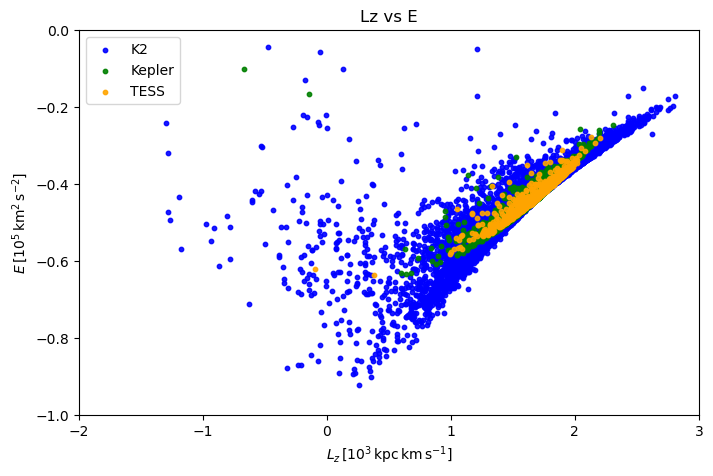

In [286]:
rel_age_dnu = df_master['RelAge_Dnu'].astype(str).str.lower() == 'true' # when using mass and radius this is  required



plt.figure(figsize=(8, 5))
plt.scatter(df_master[rel_age_dnu & K2_mask]['Lz']/1e3, df_master[rel_age_dnu & K2_mask]['E']/1e5, alpha=0.9, s=10, c='blue', label='K2')
plt.scatter(df_master[rel_age_dnu & Kepler_mask]['Lz']/1e3, df_master[rel_age_dnu &Kepler_mask]['E']/1e5, alpha=0.9,s=10, c='green', label='Kepler')
plt.scatter(df_master[rel_age_dnu & TESS_mask]['Lz']/1e3, df_master[rel_age_dnu &TESS_mask]['E']/1e5, alpha=0.9,s=10, c='orange', label='TESS')
plt.xlabel(r'$L_z\,[10^{3}\,\mathrm{kpc\,km\,s^{-1}}]$')
plt.ylabel(r'$E\,[10^{5}\,\mathrm{km^{2}\,s^{-2}}]$')
plt.title('Lz vs E')
plt.xlim(-2,3)
plt.ylim(-1,0)
#plt.grid(True, alpha=0.9)
plt.legend()
plt.show()


Next we present a diagram of orbital energy versus angular momentum. We can see the similitude between this plot and Willet et al 2024 fig 10. Which makes sense because all our stars come from that catalog. Still, the two plots do not content the same stars. Our catalog contains around 2000 stars less (17000- 15084). We can conclude that our stellar population is the same as Willet et al. 2024 

"We see that TESS sample is confined to the thin disc, Kepler extendss into thick disc and includes a few stars from the halo, K2 provides better coverage of the halo" (Wilelt et al 2024)